# Pergunta 1: como está a saúde da rede?

A base não tem meta nem ano anterior, então "indo bem ou mal" é medido contra a própria rede, com três critérios:

1. **Tendência:** o faturamento cresce, estabiliza ou cai ao longo dos 6 meses?
2. **Equilíbrio:** as 3 lojas vão bem ou uma sustenta as outras?
3. **Origem do resultado:** a variação vem de mais vendas ou de ticket maior? (isso puxa a Pergunta 2)

**Atenção à unidade:** cada linha da base é um item vendido, sem id de pedido. Por isso "receita por transação" é a receita média por linha, e não o ticket por cliente. A moeda não é informada na fonte; os valores aparecem com `$`.

As consultas ficam em `sql/pergunta_1.sql`, e este notebook lê esse arquivo.

In [3]:
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

# localiza a raiz do repositório a partir da pasta atual (funciona em notebooks/ ou na raiz)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dados" / "cafeterias.db").exists())
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

con = sqlite3.connect(RAIZ / "dados" / "cafeterias.db")

def carregar_consultas(caminho):
    """Lê o .sql e devolve {nome: consulta}, usando os marcadores '-- name: <nome>'."""
    texto = Path(caminho).read_text(encoding="utf-8")
    blocos = re.split(r"^-- name:\s*(\w+)\s*$", texto, flags=re.M)
    return {nome: sql.strip() for nome, sql in zip(blocos[1::2], blocos[2::2])}

SQL = carregar_consultas(RAIZ / "sql" / "pergunta_1.sql")

# estilo e paleta
COR = {"principal": "#6F4E37", "destaque": "#C8873A", "cinza": "#8C8C8C",
       "Astoria": "#6F4E37", "Hell's Kitchen": "#C8873A", "Lower Manhattan": "#3E7C8C"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 10})
MESES = {"2023-01": "jan", "2023-02": "fev", "2023-03": "mar", "2023-04": "abr", "2023-05": "mai", "2023-06": "jun"}

def milhar(x, casas=0):
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, casas=1):
    return f"{x:+.{casas}f}%".replace(".", ",")

## Gráfico 1: visão geral (cartões de KPI)

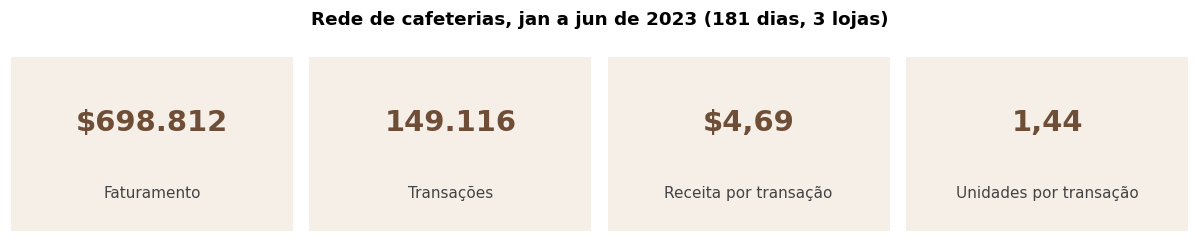

In [4]:
kpis = pd.read_sql(SQL["kpis"], con).iloc[0]

cartoes = [
    ("Faturamento", f"${milhar(kpis.faturamento)}"),
    ("Transações", milhar(kpis.transacoes)),
    ("Receita por transação", f"${milhar(kpis.receita_por_transacao, 2)}"),
    ("Unidades por transação", milhar(kpis.unidades_por_transacao, 2)),
]
fig, eixos = plt.subplots(1, 4, figsize=(11, 2.2))
for ax, (titulo, valor) in zip(eixos, cartoes):
    ax.set_facecolor("#F6EFE8"); ax.set_xticks([]); ax.set_yticks([])
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.text(0.5, 0.62, valor, ha="center", va="center", fontsize=19, fontweight="bold", color=COR["principal"])
    ax.text(0.5, 0.22, titulo, ha="center", va="center", fontsize=10, color="#444")
fig.suptitle(f"Rede de cafeterias, jan a jun de 2023 ({kpis.dias:.0f} dias, 3 lojas)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURAS / "p1_g1_kpis.png", bbox_inches="tight")
plt.show()

## Gráfico 2: faturamento mensal e variação sobre o mês anterior

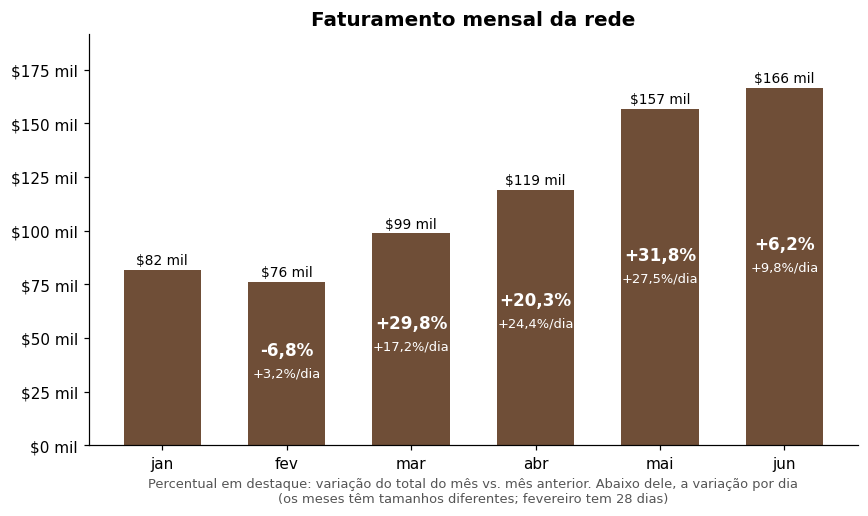

,mes,dias,faturamento,var_total_pct,fat_dia,var_dia_pct
0,2023-01,31,81677.74,NaN,2634.77,NaN
1,2023-02,28,76145.19,-6.77,2719.47,3.21
2,2023-03,31,98834.68,29.80,3188.22,17.24
3,2023-04,30,118941.08,20.34,3964.70,24.35
4,2023-05,31,156727.76,31.77,5055.73,27.52
5,2023-06,30,166485.88,6.23,5549.53,9.77


In [5]:
mensal = pd.read_sql(SQL["mensal"], con)
mensal["mes_nome"] = mensal["mes"].map(MESES)
mensal["fat_dia"] = mensal["faturamento"] / mensal["dias"]
mensal["transacoes_dia"] = mensal["transacoes"] / mensal["dias"]
# O percentual dentro da barra compara o MESMO valor que a barra desenha (o total do mês).
# Entre parênteses vai a variação por dia, que neutraliza meses com número de dias diferente.
mensal["var_total_pct"] = mensal["faturamento"].pct_change() * 100
mensal["var_dia_pct"] = mensal["fat_dia"].pct_change() * 100

fig, ax = plt.subplots(figsize=(8, 4.8))
barras = ax.bar(mensal["mes_nome"], mensal["faturamento"], color=COR["principal"], width=0.62)
for barra, (_, linha) in zip(barras, mensal.iterrows()):
    x = barra.get_x() + barra.get_width() / 2
    ax.text(x, barra.get_height() + 2500, f"${linha.faturamento/1000:,.0f} mil".replace(",", "."), ha="center", fontsize=9)
    if pd.notna(linha.var_total_pct):
        ax.text(x, barra.get_height() * 0.55, pct(linha.var_total_pct), ha="center", color="white", fontsize=11, fontweight="bold")
        ax.text(x, barra.get_height() * 0.55 - 10000, f"{pct(linha.var_dia_pct)}/dia", ha="center", color="white", fontsize=8.5)
ax.set_ylim(0, mensal["faturamento"].max() * 1.15)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f} mil".replace(",", ".")))
ax.set_title("Faturamento mensal da rede")
ax.set_xlabel("Percentual em destaque: variação do total do mês vs. mês anterior. Abaixo dele, a variação por dia\n"
              "(os meses têm tamanhos diferentes; fevereiro tem 28 dias)", fontsize=8.5, color="#555")
fig.tight_layout()
fig.savefig(FIGURAS / "p1_g2_faturamento_mensal.png", bbox_inches="tight")
plt.show()

mensal[["mes", "dias", "faturamento", "var_total_pct", "fat_dia", "var_dia_pct"]].round(2)

## Gráfico 3: faturamento mensal por loja

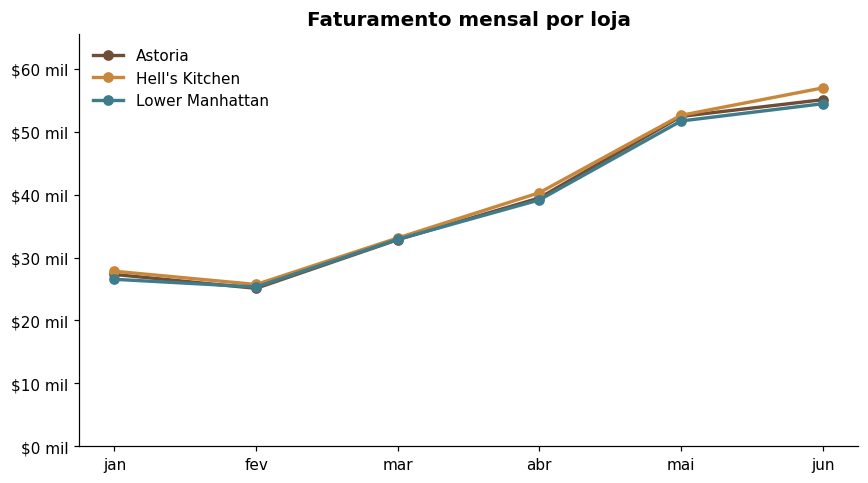

loja
Astoria            33.2
Hell's Kitchen     33.8
Lower Manhattan    32.9
Name: participação no faturamento (%), dtype: float64

In [6]:
por_loja = pd.read_sql(SQL["mensal_loja"], con)
por_loja["mes_nome"] = por_loja["mes"].map(MESES)
tabela = por_loja.pivot(index="mes_nome", columns="loja", values="faturamento").reindex(list(MESES.values()))

fig, ax = plt.subplots(figsize=(8, 4.5))
for loja in tabela.columns:
    ax.plot(tabela.index, tabela[loja], marker="o", lw=2.2, color=COR[loja], label=loja)
ax.set_ylim(0, tabela.values.max() * 1.15)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f} mil".replace(",", ".")))
ax.set_title("Faturamento mensal por loja")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURAS / "p1_g3_faturamento_por_loja.png", bbox_inches="tight")
plt.show()

participacao = por_loja.groupby("loja")["faturamento"].sum() / por_loja["faturamento"].sum() * 100
participacao.round(1).rename("participação no faturamento (%)")

## Gráfico 5: de onde vem o crescimento? (índice, janeiro = 100)

O faturamento diário é o produto de **transações por dia** e **receita por transação**. Se o faturamento acompanha as transações e a receita por transação fica parada, o crescimento vem de volume, e não de preço ou de itens maiores. Esse é o fio condutor da Pergunta 2.

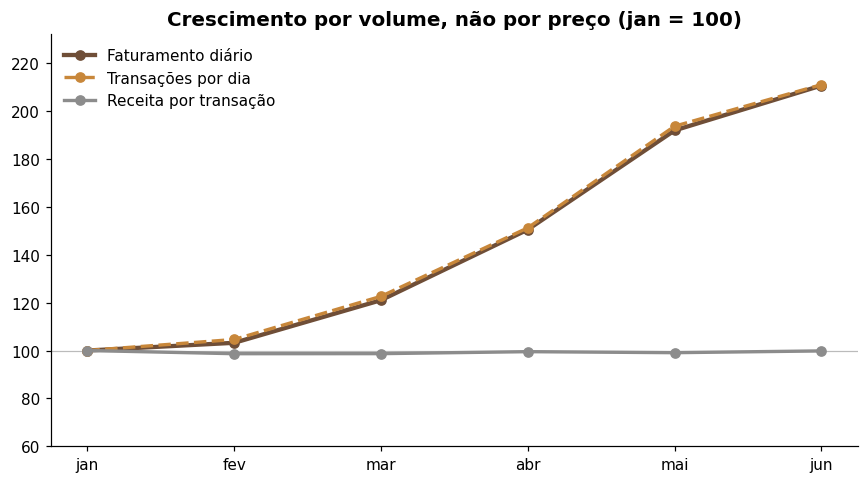

,Faturamento diário,Transações por dia,Receita por transação
mes_nome,,,
jan,100.0,100.0,100.0
fev,103.214907,104.607543,98.668704
mar,121.00565,122.611759,98.690085
abr,150.476473,151.204228,99.518694
mai,191.885525,193.640984,99.093446
jun,210.627044,210.98764,99.829091


In [7]:
mensal["receita_por_transacao"] = mensal["faturamento"] / mensal["transacoes"]
indice = pd.DataFrame({
    "Faturamento diário": mensal["fat_dia"],
    "Transações por dia": mensal["transacoes_dia"],
    "Receita por transação": mensal["receita_por_transacao"],
}).div(mensal.iloc[0][["fat_dia", "transacoes_dia", "receita_por_transacao"]].values) * 100
indice.index = mensal["mes_nome"]

estilos = {"Faturamento diário": (COR["principal"], "-", 2.8),
           "Transações por dia": (COR["destaque"], "--", 2.2),
           "Receita por transação": (COR["cinza"], "-", 2.2)}
fig, ax = plt.subplots(figsize=(8, 4.5))
for nome, (cor, estilo, largura) in estilos.items():
    ax.plot(indice.index, indice[nome], color=cor, ls=estilo, lw=largura, marker="o", label=nome)
ax.axhline(100, color="#BBB", lw=0.8, zorder=0)
ax.set_ylim(60, indice.values.max() * 1.1)
ax.set_title("Crescimento por volume, não por preço (jan = 100)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURAS / "p1_g5_decomposicao_indice.png", bbox_inches="tight")
plt.show()

indice.round(1)

## Conferência dos cálculos

In [8]:
import numpy as np

# totais: mês a mês e loja a loja precisam fechar com o total geral
assert abs(mensal["faturamento"].sum() - kpis.faturamento) < 0.01
assert mensal["transacoes"].sum() == kpis.transacoes
assert abs(tabela.to_numpy().sum() - kpis.faturamento) < 0.01
assert abs(participacao.sum() - 100) < 1e-9
# sinais: o percentual de cada barra tem o mesmo sinal da diferença entre as barras
assert (np.sign(mensal["faturamento"].diff().dropna()) == np.sign(mensal["var_total_pct"].dropna())).all()
assert (np.sign(mensal["fat_dia"].diff().dropna()) == np.sign(mensal["var_dia_pct"].dropna())).all()
# decomposição: faturamento por dia = transações por dia x receita por transação
produto = indice["Transações por dia"] * indice["Receita por transação"] / 100
assert (indice["Faturamento diário"] - produto).abs().max() < 1e-9
print("Conferência ok: totais, sinais das variações e decomposição batem.")

Conferência ok: totais, sinais das variações e decomposição batem.


## Leitura dos resultados

In [9]:
from IPython.display import Markdown

jan, fev, mai, jun = mensal.iloc[0], mensal.iloc[1], mensal.iloc[4], mensal.iloc[5]
razao = jun.fat_dia / jan.fat_dia
ps = lambda x: pct(x).lstrip("+")  # sem o sinal de + nas frases com "subiu"
loja_maior, loja_menor = participacao.idxmax(), participacao.idxmin()

Markdown(f"""
- **Tendência:** o faturamento mensal passou de ${milhar(jan.faturamento)} em janeiro para ${milhar(jun.faturamento)} em junho,
  e o faturamento médio por dia foi multiplicado por **{milhar(razao, 1)}**. Fevereiro caiu {pct(fev.var_total_pct, 1).lstrip("-")} no total,
  mas tem só 28 dias; por dia, subiu {ps(fev.var_dia_pct)}.
  O crescimento desacelerou em junho: o total do mês subiu {ps(jun.var_total_pct)} sobre maio ({ps(jun.var_dia_pct)} por dia),
  contra {ps(mai.var_total_pct)} de abril para maio ({ps(mai.var_dia_pct)} por dia).
- **Equilíbrio:** as três lojas respondem por fatias quase iguais, de {milhar(participacao.min(), 1)}% ({loja_menor})
  a {milhar(participacao.max(), 1)}% ({loja_maior}) do faturamento, e crescem juntas. Nenhuma loja sustenta as outras.
- **Origem:** as transações por dia foram multiplicadas por {milhar(jun.transacoes_dia / jan.transacoes_dia, 1)} e a receita por transação
  ficou praticamente parada (índice {milhar(indice["Receita por transação"].iloc[-1], 1)} em junho, com janeiro = 100).
  O crescimento vem de **mais vendas**, e não de preço maior ou de itens maiores.
""")


- **Tendência:** o faturamento mensal passou de $81.678 em janeiro para $166.486 em junho,
  e o faturamento médio por dia foi multiplicado por **2,1**. Fevereiro caiu 6,8% no total,
  mas tem só 28 dias; por dia, subiu 3,2%.
  O crescimento desacelerou em junho: o total do mês subiu 6,2% sobre maio (9,8% por dia),
  contra 31,8% de abril para maio (27,5% por dia).
- **Equilíbrio:** as três lojas respondem por fatias quase iguais, de 32,9% (Lower Manhattan)
  a 33,8% (Hell's Kitchen) do faturamento, e crescem juntas. Nenhuma loja sustenta as outras.
- **Origem:** as transações por dia foram multiplicadas por 2,1 e a receita por transação
  ficou praticamente parada (índice 99,8 em junho, com janeiro = 100).
  O crescimento vem de **mais vendas**, e não de preço maior ou de itens maiores.


**Resposta curta à Pergunta 1:** a rede vai bem, com crescimento forte, distribuído entre as lojas e puxado por volume.

**Cuidados na leitura:**
- São só seis meses e não há ano anterior. Parte da alta pode ser sazonalidade (por exemplo, clima mais quente), e a base não permite separar isso.
- Sem meta, "bem" significa apenas crescimento em relação a janeiro.
- A desaceleração de junho merece atenção, mas um único mês não confirma uma tendência.

**Próxima pergunta (Pergunta 2):** se o crescimento é de volume, o que o explica? Candidatos: quais produtos e categorias ganharam volume, em que horários e dias, e se o aumento vem de mais clientes em cada loja ou de mais itens por visita. Também entra aqui a investigação dos 15 produtos com preços diferentes.